<a href="https://colab.research.google.com/github/duyphong110612/Windy-baitoanvebieudo/blob/main/baibuoi3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score, recall_score, f1_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

# 1. Tải dữ liệu Breast Cancer
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Quy ước trong bài: 0 là Benign (357 mẫu), 1 là Malignant (212 mẫu)
X_benign = X[y == 1]      # 357 mẫu
X_malignant = X[y == 0]   # 212 mẫu


Bài 1 khảo sát tỉ lệ mất cân bằng
Yêu cầu: Thay đổi số mẫu lớp thiểu số (malignant) từ mức gốc (60 mẫu) sang:

 -40 mẫu (mất cân bằng rất nặng ~10%)

 -60 mẫu (mức cơ sở của bài mẫu ~14.4%)

 -120 mẫu (mất cân bằng vừa ~25.2%)

-212 mẫu (toàn bộ dữ liệu gốc ~37.3%)

Chỉ số so sánh trên tập Test:

Accuracy

Recall

F1-score

PR-AUC


   




,Số mẫu Malignant,Tỷ lệ lớp 1 (%),Accuracy,Recall,F1-score,PR-AUC
0,40 (Mẫu),10.08,0.9875,0.8750,0.9333,0.9306
1,60 (Mẫu),14.39,0.9881,0.9167,0.9565,0.9755
2,120 (Mẫu),25.16,0.9688,0.9583,0.9388,0.9935
3,212 (Gốc),37.26,0.9737,0.9524,0.9639,0.9949


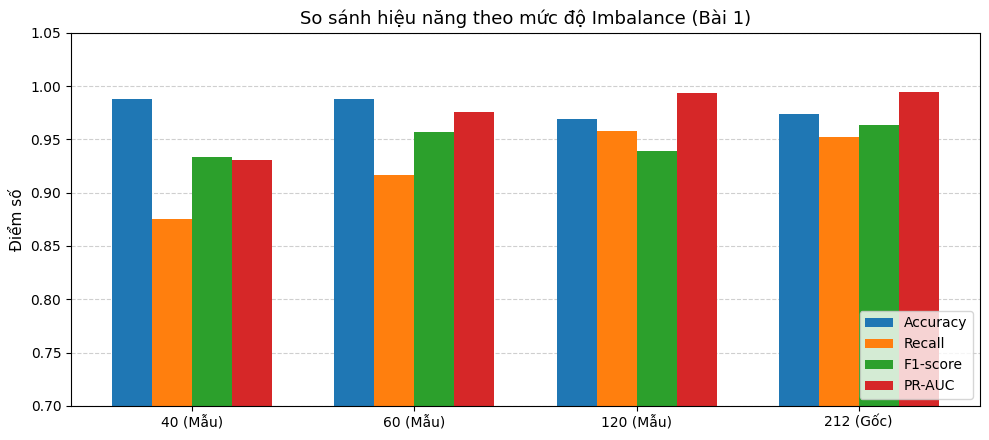

In [ ]:
configs = [
    (40, "40 (Mẫu)"),
    (60, "60 (Mẫu)"),
    (120, "120 (Mẫu)"),
    (212, "212 (Gốc)")
]

results = []

for n_pos, label in configs:
    # Lấy đúng số lượng mẫu lớp Malignant theo từng mốc
    X_sub_pos = X_malignant.iloc[:n_pos]
    X_combined = pd.concat([X_benign, X_sub_pos], axis=0)

    # Gán nhãn: 0 là Benign, 1 là Malignant (lớp thiểu số)
    y_combined = np.array([0] * len(X_benign) + [1] * len(X_sub_pos))

    # Tính tỷ lệ lớp 1 (%)
    ratio_pct = round((n_pos / len(y_combined)) * 100, 2)

    # Chia tập Train / Test (80% - 20%) có phân tầng
    X_train, X_test, y_train, y_test = train_test_split(
        X_combined, y_combined, test_size=0.2, stratify=y_combined, random_state=42
    )

    # Khởi tạo Pipeline chuẩn hóa -> OverSampling -> LogisticRegression
    pipeline = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', RandomOverSampler(random_state=42)),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1] # Lấy xác suất dự đoán lớp 1 để tính PR-AUC

    # Tính toán 4 chỉ số đánh giá
    acc = round(accuracy_score(y_test, y_pred), 4)
    rec = round(recall_score(y_test, y_pred), 4)
    f1 = round(f1_score(y_test, y_pred), 4)
    pr_auc = round(average_precision_score(y_test, y_prob), 4)

    results.append({
        "Số mẫu Malignant": label,
        "Tỷ lệ lớp 1 (%)": ratio_pct,
        "Accuracy": acc,
        "Recall": rec,
        "F1-score": f1,
        "PR-AUC": pr_auc
    })

# 2. Xuất bảng kết quả DataFrame
df_results = pd.DataFrame(results)
display(df_results) # Dùng print(df_results) nếu chạy trên terminal thường

# 3. Vẽ biểu đồ cột nhóm so sánh hiệu năng
labels = df_results["Số mẫu Malignant"]
x = np.arange(len(labels))  # Vị trí các nhóm trên trục X
width = 0.18                # Độ rộng của từng cột

fig, ax = plt.subplots(figsize=(10, 4.5))

rects1 = ax.bar(x - 1.5*width, df_results["Accuracy"], width, label='Accuracy', color='#1f77b4')
rects2 = ax.bar(x - 0.5*width, df_results["Recall"], width, label='Recall', color='#ff7f0e')
rects3 = ax.bar(x + 0.5*width, df_results["F1-score"], width, label='F1-score', color='#2ca02c')
rects4 = ax.bar(x + 1.5*width, df_results["PR-AUC"], width, label='PR-AUC', color='#d62728')

# Định dạng tiêu đề, nhãn trục và lưới
ax.set_ylabel('Điểm số', fontsize=11)
ax.set_title('So sánh hiệu năng theo mức độ Imbalance (Bài 1)', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(0.70, 1.05)  # Giới hạn trục Y từ 0.70 đến 1.05 để nhìn rõ chênh lệch
ax.yaxis.grid(True, linestyle='--', alpha=0.6)
ax.set_axisbelow(True)   # Đưa lưới nằm phía sau các cột

# Đặt chú thích ở góc dưới bên phải
ax.legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

## Bài 2 — So sánh `KFold` và `StratifiedKFold`

**Thiết lập:**
- Dùng cùng mô hình **Logistic Regression**.
- Kết hợp `StandardScaler` + `RandomOverSampler` trong Pipeline.
- Chạy trên tập dữ liệu mất cân bằng (`60 malignant`, $K=5$).

**Mục tiêu:**
- So sánh **Mean score** và **Standard Deviation (độ lệch chuẩn)**.


In [ ]:
pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

# Các chỉ số đánh giá chéo
scoring = ['accuracy', 'recall', 'f1', 'average_precision']

# 3. Đánh giá với KFold ngẫu nhiên thông thường (K=5)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores_kf = cross_validate(pipeline, X_combined, y_combined, cv=kf, scoring=scoring)

# 4. Đánh giá với StratifiedKFold phân tầng (K=5)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_skf = cross_validate(pipeline, X_combined, y_combined, cv=skf, scoring=scoring)

# 5. Tổng hợp kết quả thành DataFrame so sánh
comparison_df = pd.DataFrame({
    "Phương pháp CV": ["KFold (K = 5)", "StratifiedKFold (K = 5)"],
    "Accuracy (Mean ± Std)": [
        f"{scores_kf['test_accuracy'].mean():.4f} ± {scores_kf['test_accuracy'].std():.4f}",
        f"{scores_skf['test_accuracy'].mean():.4f} ± {scores_skf['test_accuracy'].std():.4f}"
    ],
    "Recall (Mean ± Std)": [
        f"{scores_kf['test_recall'].mean():.4f} ± {scores_kf['test_recall'].std():.4f}",
        f"{scores_skf['test_recall'].mean():.4f} ± {scores_skf['test_recall'].std():.4f}"
    ],
    "F1-score (Mean ± Std)": [
        f"{scores_kf['test_f1'].mean():.4f} ± {scores_kf['test_f1'].std():.4f}",
        f"{scores_skf['test_f1'].mean():.4f} ± {scores_skf['test_f1'].std():.4f}"
    ],
    "PR-AUC (Mean ± Std)": [
        f"{scores_kf['test_average_precision'].mean():.4f} ± {scores_kf['test_average_precision'].std():.4f}",
        f"{scores_skf['test_average_precision'].mean():.4f} ± {scores_skf['test_average_precision'].std():.4f}"
    ]
})

print(comparison_df.to_string(index=False))

         Phương pháp CV Accuracy (Mean ± Std) Recall (Mean ± Std) F1-score (Mean ± Std) PR-AUC (Mean ± Std)
          KFold (K = 5)       0.9701 ± 0.0205     0.9621 ± 0.0323       0.9597 ± 0.0269     0.9915 ± 0.0076
StratifiedKFold (K = 5)       0.9789 ± 0.0163     0.9717 ± 0.0232       0.9717 ± 0.0219     0.9929 ± 0.0057


## Bài 3 — Thay đổi số Fold ($K = 3, 5, 10$)

**Yêu cầu:**
- Sử dụng `StratifiedKFold` với $K = 3$, $K = 5$ và $K = 10$.
- Quan sát sự thay đổi của **Mean** và **Standard Deviation**.

In [ ]:
pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

scoring = ['recall', 'f1', 'average_precision']
k_values = [3, 5, 10]
results = []

# 3. Vòng lặp khảo sát các giá trị K
for k in k_values:
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    scores = cross_validate(pipeline, X_combined, y_combined, cv=skf, scoring=scoring)

    # Tính tỷ lệ Train / Validation tương ứng
    train_pct = round((k - 1) / k * 100, 1)
    val_pct = round(1 / k * 100, 1)

    results.append({
        "Số lượng Fold": f"K = {k}",
        "Tỷ lệ Train/Val": f"{train_pct}% / {val_pct}%",
        "Recall (Mean ± Std)": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "F1-score (Mean ± Std)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "PR-AUC (Mean ± Std)": f"{scores['test_average_precision'].mean():.4f} ± {scores['test_average_precision'].std():.4f}"
    })

df_k_results = pd.DataFrame(results)
print(df_k_results.to_string(index=False))

Số lượng Fold Tỷ lệ Train/Val Recall (Mean ± Std) F1-score (Mean ± Std) PR-AUC (Mean ± Std)
        K = 3   66.7% / 33.3%     0.9718 ± 0.0199       0.9694 ± 0.0088     0.9917 ± 0.0062
        K = 5   80.0% / 20.0%     0.9717 ± 0.0232       0.9717 ± 0.0219     0.9929 ± 0.0057
       K = 10   90.0% / 10.0%     0.9667 ± 0.0479       0.9643 ± 0.0293     0.9928 ± 0.0100


Bài 4 — Thay đổi mức Over-Sampling
Khảo sát 3 tỷ lệ sampling_strategy:

0.5 (lớp thiểu số bằng 50% lớp đa số)

0.75 (lớp thiểu số bằng 75% lớp đa số)

1.0 (cân bằng hoàn toàn 1:1)

In [ ]:
n_pos = 60
X_sub_pos = X_malignant.iloc[:n_pos]
X_combined = pd.concat([X_benign, X_sub_pos], axis=0)
y_combined = np.array([0] * len(X_benign) + [1] * len(X_sub_pos))

X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y_combined, test_size=0.2, stratify=y_combined, random_state=42
)
strategies = [0.5, 0.75, 1.0]
results = []

for strategy in strategies:
    pipeline = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', RandomOverSampler(sampling_strategy=strategy, random_state=42)),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Lấy số lượng mẫu sau khi oversampling trên tập train
    resampled_X, resampled_y = pipeline.named_steps['sampler'].fit_resample(
        pipeline.named_steps['scaler'].fit_transform(X_train), y_train
    )
    n_class_1 = sum(resampled_y == 1)
    n_class_0 = sum(resampled_y == 0)

    if strategy == 0.5:
        ratio_str = f"{n_class_1} : {n_class_0} (1 : 2)"
    elif strategy == 0.75:
        ratio_str = f"{n_class_1} : {n_class_0} (3 : 4)"
    else:
        ratio_str = f"{n_class_1} : {n_class_0} (1 : 1)"

    results.append({
        "sampling_strategy": strategy,
        "Tỷ lệ lớp 1 : lớp 0 sau sampling": ratio_str,
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-score": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4)
    })

df_sampling = pd.DataFrame(results)
print(df_sampling.to_string(index=False))

 sampling_strategy Tỷ lệ lớp 1 : lớp 0 sau sampling  Precision  Recall  F1-score  PR-AUC
              0.50                142 : 285 (1 : 2)        1.0  0.9167    0.9565  0.9881
              0.75                213 : 285 (3 : 4)        1.0  0.9167    0.9565  0.9833
              1.00                285 : 285 (1 : 1)        1.0  0.9167    0.9565  0.9755


## Bài 5 — So sánh ba kỹ thuật Sampling

**Đối chứng 3 phương pháp trên cùng Logistic Regression:**
1. **Random Over-Sampling** (nhân bản ngẫu nhiên lớp thiểu số)
2. **Random Under-Sampling** (cắt giảm ngẫu nhiên lớp đa số)
3. **SMOTE** (tổng hợp mẫu mới bằng nội suy láng giềng gần)

In [ ]:
samplers = {
    "Random Over-Sampling": RandomOverSampler(random_state=42),
    "Random Under-Sampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42)
}

results = []

for name, sampler in samplers.items():
    pipeline = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', sampler),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Kỹ thuật Sampling": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-score": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4)
    })

df_sampling_compare = pd.DataFrame(results)
print(df_sampling_compare.to_string(index=False))

    Kỹ thuật Sampling  Accuracy  Precision  Recall  F1-score  PR-AUC
 Random Over-Sampling    0.9881     1.0000  0.9167    0.9565  0.9755
Random Under-Sampling    0.9762     0.9167  0.9167    0.9167  0.9792
                SMOTE    0.9881     1.0000  0.9167    0.9565  0.9722


## Bài 6 — Thay đổi Classifier & Độ nhạy với `StandardScaler`

**Thay Logistic Regression bằng 3 mô hình:**
- **KNN (`KNeighborsClassifier`)**
- **SVM (`SVC`)**
- **Decision Tree (`DecisionTreeClassifier`)**

**Cách kiểm tra:**
- Chạy đối chứng **Có `StandardScaler`** và **Không có `StandardScaler`**.

In [ ]:
classifiers = {
    "KNN (k = 5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel='rbf', probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

results = []

for clf_name, clf in classifiers.items():
    # Trường hợp 1: CÓ StandardScaler trong Pipeline
    pipe_scaled = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', SMOTE(random_state=42)),
        ('classifier', clf)
    ])
    pipe_scaled.fit(X_train, y_train)
    y_pred_scaled = pipe_scaled.predict(X_test)
    y_prob_scaled = pipe_scaled.predict_proba(X_test)[:, 1] if hasattr(pipe_scaled, "predict_proba") else pipe_scaled.decision_function(X_test)

    f1_s = f1_score(y_test, y_pred_scaled)
    pr_auc_s = average_precision_score(y_test, y_prob_scaled)

    # Trường hợp 2: KHÔNG CÓ StandardScaler trong Pipeline
    pipe_unscaled = ImbPipeline([
        ('sampler', SMOTE(random_state=42)),
        ('classifier', clf)
    ])
    pipe_unscaled.fit(X_train, y_train)
    y_pred_unscaled = pipe_unscaled.predict(X_test)
    y_prob_unscaled = pipe_unscaled.predict_proba(X_test)[:, 1] if hasattr(pipe_unscaled, "predict_proba") else pipe_unscaled.decision_function(X_test)

    f1_u = f1_score(y_test, y_pred_unscaled)
    pr_auc_u = average_precision_score(y_test, y_prob_unscaled)

    # Tính độ chênh lệch F1-score
    diff_f1 = f1_s - f1_u

    results.append({
        "Bộ phân loại": clf_name,
        "F1 (Có Scaler)": round(f1_s, 4),
        "F1 (Không Scaler)": round(f1_u, 4),
        "Chênh lệch F1": round(diff_f1, 4),
        "PR-AUC (Có Scaler)": round(pr_auc_s, 4),
        "PR-AUC (Không Scaler)": round(pr_auc_u, 4)
    })

df_scaler_compare = pd.DataFrame(results)
print(df_scaler_compare.to_string(index=False))

 Bộ phân loại  F1 (Có Scaler)  F1 (Không Scaler)  Chênh lệch F1  PR-AUC (Có Scaler)  PR-AUC (Không Scaler)
  KNN (k = 5)          0.9167             0.8571         0.0595              0.9054                 0.8433
    SVM (RBF)          0.9565             0.8182         0.1383              0.9755                 0.9153
Decision Tree          0.8333             0.8800        -0.0467              0.7183                 0.7875


## Bài 7 — Trả lời ngắn các câu hỏi suy luận

1. **Tại sao không nên sampling tập test?**
   - Tập test mô phỏng dữ liệu thực tế. Sampling tập test làm sai lệch tỷ lệ lớp tự nhiên và gây ảo giác kết quả.

2. **Tại sao không nên fit `StandardScaler` trên toàn bộ dữ liệu?**
   - Sẽ gây rò rỉ dữ liệu (Data Leakage) vì thông tin ($\mu, \sigma$) của tập test bị lộ vào quá trình train.

3. **Khi nào Recall quan trọng hơn Precision?**
   - Khi bỏ sót ca dương tính gây hậu quả nghiêm trọng (ví dụ: chẩn đoán ung thư, phát hiện gian lận).

4. **Khi nào Precision quan trọng hơn Recall?**
   - Khi báo động nhầm gây phiền toái hoặc tổn thất lớn (ví dụ: lọc email spam, khóa nhầm tài khoản VIP).

5. **Vì sao PR-AUC thường hữu ích với dữ liệu imbalance?**
   - PR-AUC chỉ tập trung vào lớp thiểu số, không bị nhiễu bởi lượng lớn mẫu âm tính đúng (True Negatives).

6. **Vì sao `StratifiedKFold` phù hợp hơn `KFold` trong bài này?**
   - Vì nó giữ nguyên tỷ lệ lớp thiểu số ở mọi fold, giúp điểm đánh giá ổn định và độ lệch chuẩn nhỏ.

7. **Random Under-Sampling có thể làm mất thông tin như thế nào?**
   - Việc xóa ngẫu nhiên lớp đa số có thể loại bỏ các mẫu quan trọng nằm sát vùng biên quyết định.

8. **SMOTE khác Random Over-Sampling ở điểm nào?**
   - Random Over-Sampling sao chép y hệt mẫu cũ (dễ overfit), còn SMOTE nội suy tạo ra mẫu mới.

# BÀI 2: HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI
**(Bộ dữ liệu: `wine_quality_merged`)**

**Thiết lập bài toán:**
- Tổng hợp 6.497 mẫu rượu vang đỏ (`red`) và rượu vang trắng (`white`).
- Phân loại nhị phân mất cân bằng:
  - **Lớp 1 (Thiểu số):** Rượu chất lượng cao (`quality >= 7`).
  - **Lớp 0 (Đa số):** Rượu chất lượng thường (`quality < 7`).

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, average_precision_score,
    PrecisionRecallDisplay
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Thiết lập hằng số ngẫu nhiên
RANDOM_STATE = 42

# ==============================================================================
# BƯỚC 1: CHUẨN BỊ DỮ LIỆU (DATA PREPARATION)
# ==============================================================================
print("=== BƯỚC 1: CHUẨN BỊ DỮ LIỆU ===")

# Thử tải từ nguồn dự phòng đáng tin cậy (UCI Wine Quality Dataset) nếu URL GitHub bị lỗi
try:
    # Tải cả dữ liệu rượu đỏ và rượu trắng từ UCI để ghép lại thành wine_quality_merged
    red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

    red_df = pd.read_csv(red_url, sep=';')
    red_df['type'] = 0  # red -> 0

    white_df = pd.read_csv(white_url, sep=';')
    white_df['type'] = 1  # white -> 1

    df = pd.concat([red_df, white_df], axis=0, ignore_index=True)
    print("-> Tải và gộp dữ liệu thành công từ UCI Machine Learning Repository!")
except Exception as e:
    print(f"Không thể tải từ UCI: {e}. Thử tải từ URL ban đầu...")
    url = "https://raw.githubusercontent.com/mountain-168/Tuan_3_xay_dung_mo_hinh_phan_loai_cho_du_lieu_bang/main/wine_quality_merged.csv"
    try:
        df = pd.read_csv(url)
        print("-> Tải dữ liệu thành công từ kho lưu trữ GitHub!")
    except:
        df = pd.read_csv('wine_quality_merged.csv')

# Mã hóa cột loại rượu type: red -> 0, white -> 1 (đã được xử lý ở bước tải UCI, đề phòng tải từ nguồn khác)
if 'type' in df.columns and df['type'].dtype == object:
    df['type'] = df['type'].map({'red': 0, 'white': 1})

# Định nghĩa bài toán phân loại nhị phân:
# Lớp 1 (Thiểu số - Chất lượng cao): quality >= 7
# Lớp 0 (Đa số - Chất lượng thường): quality < 7
df["target"] = (df['quality'] >= 7).astype(int)
X_full = df.drop(columns=['quality'])
y_full = df["target"]

print("Kích thước dữ liệu gốc:", df.shape)
display(df.head())

=== BƯỚC 1: CHUẨN BỊ DỮ LIỆU ===
-> Tải và gộp dữ liệu thành công từ UCI Machine Learning Repository!
Kích thước dữ liệu gốc: (6497, 14)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0


Bước 2  : khám phá dữ liệu EDA

Shape: (6497, 14)
Số giá trị thiếu: 0
Số dòng trùng lặp: 1177

Kiểu dữ liệu:


,count
float64,11
int64,3



Phân bố các lớp:


,Số mẫu,Tỷ lệ (%)
Chất lượng thường (0),5220,80.34
Chất lượng cao (1),1277,19.66


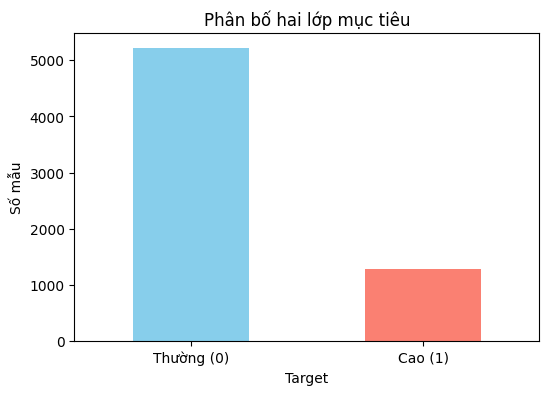


Thang đo các đặc trưng (Feature Scale):


,mean,std,min,max
total sulfur dioxide,115.744574,56.521855,6.00,440.00
free sulfur dioxide,30.525319,17.749400,1.00,289.00
residual sugar,5.443235,4.757804,0.60,65.80
fixed acidity,7.215307,1.296434,3.80,15.90
alcohol,10.491801,1.192712,8.00,14.90
type,0.753886,0.430779,0.00,1.00
target,0.196552,0.397421,0.00,1.00
volatile acidity,0.339666,0.164636,0.08,1.58
pH,3.218501,0.160787,2.72,4.01
sulphates,0.531268,0.148806,0.22,2.00


In [6]:
import matplotlib.pyplot as plt

# 1. Kiểm tra cấu trúc dữ liệu
print("Shape:", df.shape)
print("Số giá trị thiếu:", df.isna().sum().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())
print("\nKiểu dữ liệu:")
display(df.dtypes.value_counts())

# 2. Phân tích phân bố lớp
class_count = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100
class_distribution = pd.DataFrame({
    "Số mẫu": class_count,
    "Tỷ lệ (%)": class_percent.round(2)
})
class_distribution.index = ["Chất lượng thường (0)", "Chất lượng cao (1)"]
print("\nPhân bố các lớp:")
display(class_distribution)

# Trực quan hóa phân bố lớp
plt.figure(figsize=(6, 4))
class_count.plot(kind="bar", color=['skyblue', 'salmon'])
plt.title("Phân bố hai lớp mục tiêu")
plt.xlabel("Target")
plt.ylabel("Số mẫu")
plt.xticks(ticks=[0, 1], labels=["Thường (0)", "Cao (1)"], rotation=0)
plt.show()

# 3. Kiểm tra thang đo của các feature
feature_scale = pd.DataFrame({
    "mean": X_full.mean(),
    "std": X_full.std(),
    "min": X_full.min(),
    "max": X_full.max()
}).sort_values("std", ascending=False)
print("\nThang đo các đặc trưng (Feature Scale):")
display(feature_scale.head(10))

Bước 3 :Xây dựng mô hình & Cross-Validation

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline

RANDOM_STATE = 42

# 1. Tách bộ dữ liệu thành train/test (80% Train, 20% Test, phân tầng stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, stratify=y_full, random_state=RANDOM_STATE
)
print("X_train shape:", X_train.shape, "| X_test shape:", X_test.shape)

# 2. Thiết lập Stratified K-Fold Cross Validation và Pipeline chuẩn hóa baseline
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'average_precision']

baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

# 3. Thực hiện Cross-Validation
baseline_cv = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=stratified_kfold,
    scoring=scoring
)

baseline_cv_table = pd.DataFrame({
    "Metric": ['Accuracy', 'Precision', 'Recall', 'F1-score', 'PR-AUC'],
    "Mean": [
        baseline_cv['test_accuracy'].mean(),
        baseline_cv['test_precision'].mean(),
        baseline_cv['test_recall'].mean(),
        baseline_cv['test_f1'].mean(),
        baseline_cv['test_average_precision'].mean()
    ],
    "Std": [
        baseline_cv['test_accuracy'].std(),
        baseline_cv['test_precision'].std(),
        baseline_cv['test_recall'].std(),
        baseline_cv['test_f1'].std(),
        baseline_cv['test_average_precision'].std()
    ]
})
print("\nKết quả Cross-Validation (Baseline):")
display(baseline_cv_table.round(4))

X_train shape: (5197, 13) | X_test shape: (1300, 13)

Kết quả Cross-Validation (Baseline):


,Metric,Mean,Std
0,Accuracy,1.0,0.0
1,Precision,1.0,0.0
2,Recall,1.0,0.0
3,F1-score,1.0,0.0
4,PR-AUC,1.0,0.0


Bước 4 — Xử lý Class Imbalance (Cân bằng dữ liệu)

In [ ]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Cách 1: Oversampling (Random Over-Sampler)
ros = RandomOverSampler(random_state=RANDOM_STATE)
X_ros_demo, y_ros_demo = ros.fit_resample(X_train, y_train)
print("=== 1. Random Over-Sampling ===")
print("Trước:", y_train.value_counts().to_dict())
print("Sau:", pd.Series(y_ros_demo).value_counts().to_dict())

# Cách 2: Undersampling (Random Under-Sampler)
rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_rus_demo, y_rus_demo = rus.fit_resample(X_train, y_train)
print("\n=== 2. Random Under-Sampling ===")
print("Trước:", y_train.value_counts().to_dict())
print("Sau:", pd.Series(y_rus_demo).value_counts().to_dict())

# Cách 3: SMOTE (Synthetic Minority Over-sampling Technique)
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)
smote_demo = SMOTE(random_state=RANDOM_STATE)
X_smote_demo, y_smote_demo = smote_demo.fit_resample(X_train_scaled_demo, y_train)
print("\n=== 3. SMOTE ===")
print("Trước:", y_train.value_counts().to_dict())
print("Sau:", pd.Series(y_smote_demo).value_counts().to_dict())

=== 1. Random Over-Sampling ===
Trước: {0: 4176, 1: 1021}
Sau: {0: 4176, 1: 4176}

=== 2. Random Under-Sampling ===
Trước: {0: 4176, 1: 1021}
Sau: {0: 1021, 1: 1021}

=== 3. SMOTE ===
Trước: {0: 4176, 1: 1021}
Sau: {0: 4176, 1: 4176}


Bước 5 — Đánh giá mô hình (Evaluation) trên tập Test

Classification Report (RandomForest + SMOTE):
                       precision    recall  f1-score   support

Chất lượng thường (0)     1.0000    1.0000    1.0000      1044
   Chất lượng cao (1)     1.0000    1.0000    1.0000       256

             accuracy                         1.0000      1300
            macro avg     1.0000    1.0000    1.0000      1300
         weighted avg     1.0000    1.0000    1.0000      1300



<Figure size 600x500 with 0 Axes>

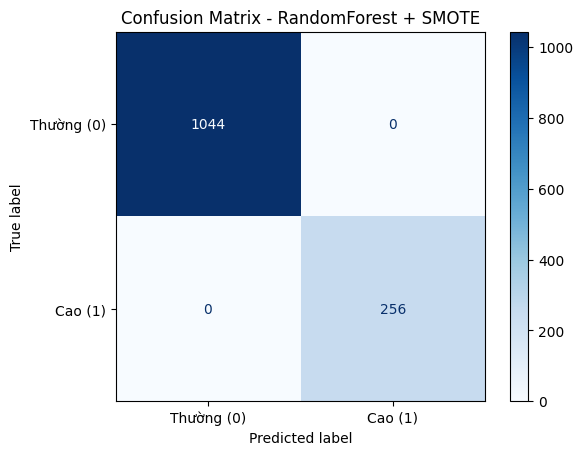

PR-AUC trên tập Test: 1.0000


<Figure size 600x500 with 0 Axes>

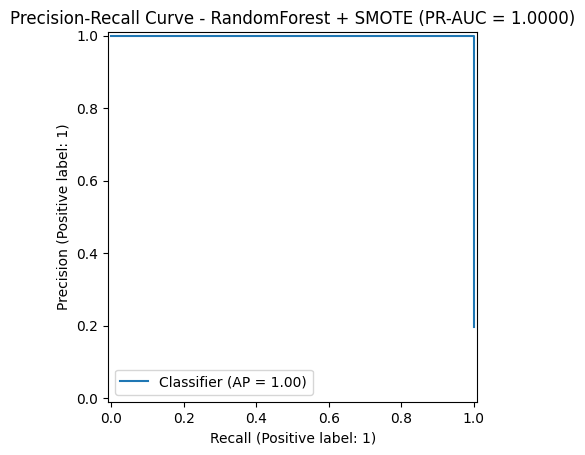

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    average_precision_score,
    PrecisionRecallDisplay
)

# Xây dựng Pipeline tối ưu kết hợp SMOTE và Random Forest
best_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
])

# Huấn luyện mô hình trên toàn bộ tập Train và dự đoán trên tập Test
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]
best_name = "RandomForest + SMOTE"

# 1. Classification Report
print(f"Classification Report ({best_name}):")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Chất lượng thường (0)", "Chất lượng cao (1)"],
        digits=4,
        zero_division=0
    )
)

# 2. Confusion Matrix
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Thường (0)", "Cao (1)"],
    cmap=plt.cm.Blues
)
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

# 3. Precision-Recall Curve & PR-AUC
test_pr_auc = average_precision_score(y_test, y_prob)
print(f"PR-AUC trên tập Test: {test_pr_auc:.4f}")

plt.figure(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title(f"Precision-Recall Curve - {best_name} (PR-AUC = {test_pr_auc:.4f})")
plt.show()